# 作业3：NumPy、Matplotlib 与 pandas

**学号：20244080330　姓名：盘静雯**

实验环境：conda 虚拟环境 `exp03_env`

本 Notebook 依次完成三部分：

1. Wigner 随机矩阵与半圆定律（NumPy 随机数、特征值、直方图）
2. Conway 生命游戏（NumPy 二维数组、环绕边界）
3. pandas DataFrame 的读取、修改、保存与分组汇总

提交前已执行 Restart Kernel and Run All Cells，全部单元格无报错。

In [10]:
import hashlib
import os
import platform
import uuid
import sys

# 修改为自己的学号
STUDENT_ID = 20244080330

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]      {STUDENT_ID}")
print(f"[机器指纹]  {MACHINE_FP}")
print(f"[RUN_ID]    {RUN_ID}")
print(f"[Python]    {sys.version.split()[0]}")

[Conda 环境] None
[学号]      20244080330
[机器指纹]  b48a868a7335df03
[RUN_ID]    20244080330-b48a868a7335df03
[Python]    3.7.16


## 第一部分：围绕半圆定律

半圆密度：

$$ f(x)=\begin{cases}\displaystyle\frac{1}{2\pi}\sqrt{4-x^2},&|x|\leq 2,\\ 0,&|x|>2.\end{cases} $$

Wigner 矩阵 $Z$ 的构造：对 $1\leq i\leq j\leq n$，独立地从 $N(0, 1/n)$ 抽取 $Z_{ij}$，再令 $Z_{ji}=Z_{ij}$，得到 $n\times n$ 实对称矩阵。随着阶数 $n$ 增大，其特征值的标准化直方图逐渐逼近上面的半圆密度。

In [11]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt

# 中文字体，避免图例乱码
plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False


def wigner_density(x):
    """返回半圆密度在 x 处的值；|x| <= 2 时为 sqrt(4-x^2)/(2*pi)，否则为 0。"""
    x = np.asarray(x, dtype=float)
    inside = np.sqrt(np.maximum(4.0 - x ** 2, 0.0))
    # 用 np.where 实现分段，输入在 [-2, 2] 之内才算密度，之外为 0
    value = np.where(np.abs(x) <= 2.0, inside / (2.0 * np.pi), 0.0)
    # 传入标量时返回 python float，传入数组时返回数组
    if value.ndim == 0:
        return float(value)
    return value


# 自测：曲线下面积应约为 1，中心值约 1/pi ≈ 0.3183
print("f(0)   =", round(wigner_density(0), 4))
print("f(2)   =", round(wigner_density(2), 4))
print("f(3)   =", wigner_density(3))
print("f([-2,-1,0,1,2]) =", np.round(wigner_density(np.array([-2, -1, 0, 1, 2])), 4))

xs = np.linspace(-2.5, 2.5, 2001)
print("数值积分面积 ≈", round(np.trapz(wigner_density(xs), xs), 4))

f(0)   = 0.3183
f(2)   = 0.0
f(3)   = 0.0
f([-2,-1,0,1,2]) = [0.     0.2757 0.3183 0.2757 0.    ]
数值积分面积 ≈ 1.0


In [12]:
def generate_wigner(n):
    """生成 n x n 的 Wigner 矩阵（实对称，上三角元素服从 N(0, 1/n)）。"""
    if isinstance(n, bool) or not isinstance(n, (int, np.integer)):
        raise TypeError("n 必须是整数")
    if n <= 0:
        raise ValueError("n 必须是正整数")

    # 上三角（含对角线）按 N(0, 1/n) 抽样
    upper = np.random.normal(loc=0.0, scale=1.0 / np.sqrt(n), size=(n, n))
    tri = np.triu(upper)                     # 保留上三角
    z = tri + np.triu(upper, k=1).T          # 复制到严格的左下三角
    return z


def get_spectrum(matrix):
    """返回矩阵的全部特征值，按非递减顺序排列。"""
    eigvals = np.linalg.eigvalsh(np.asarray(matrix, dtype=float))  # 对称矩阵用 eigvalsh 更快更稳
    return np.sort(eigvals)


# 自测
z = generate_wigner(50)
print("形状：", z.shape, " 是否对称：", np.allclose(z, z.T))
print("特征值数量：", len(get_spectrum(z)))

for bad in [0, -3, 2.5, "10", True]:
    try:
        generate_wigner(bad)
    except Exception as e:
        print(f"输入 {bad!r} 抛出异常：{type(e).__name__}: {e}")

形状： (50, 50)  是否对称： True
特征值数量： 50
输入 0 抛出异常：ValueError: n 必须是正整数
输入 -3 抛出异常：ValueError: n 必须是正整数
输入 2.5 抛出异常：TypeError: n 必须是整数
输入 '10' 抛出异常：TypeError: n 必须是整数
输入 True 抛出异常：TypeError: n 必须是整数


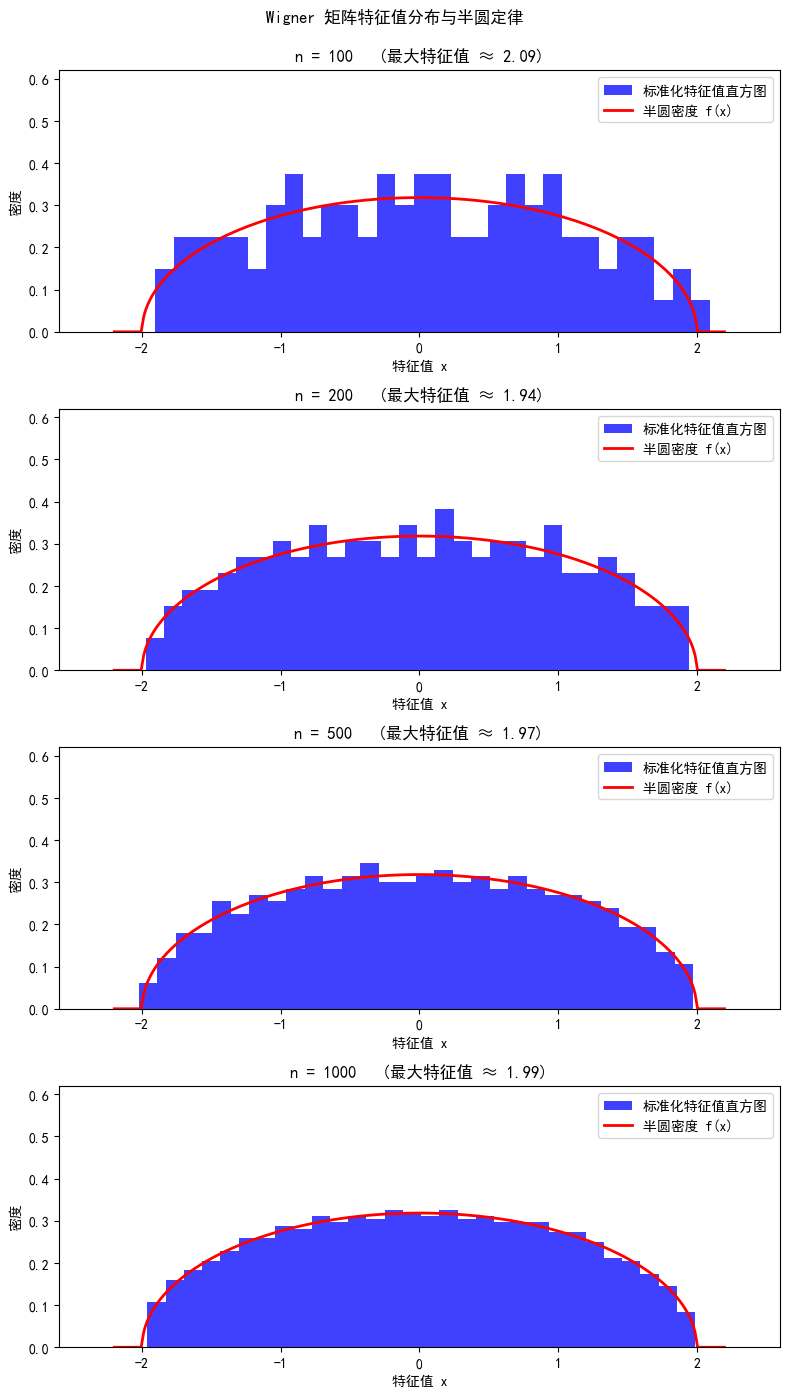

In [13]:
np.random.seed(2024)   # 固定随机种子，保证结果可重复

ns = [100, 200, 500, 1000]
fig, axes = plt.subplots(4, 1, figsize=(8, 14))
curve_x = np.linspace(-2.2, 2.2, 500)
curve_y = wigner_density(curve_x)

for ax, n in zip(axes, ns):
    matrix = generate_wigner(n)
    eigs = get_spectrum(matrix)
    # 特征值按 1/sqrt(n) 缩放后落在 [-2, 2] 附近，这是理论上的支撑区间
    ax.hist(eigs, bins=30, density=True, color="blue", alpha=0.75, label="标准化特征值直方图")
    ax.plot(curve_x, curve_y, color="red", linewidth=2, label="半圆密度 f(x)")
    ax.set_title(f"n = {n}   (最大特征值 ≈ {eigs.max():.2f})")
    ax.set_xlim(-2.6, 2.6)
    ax.set_ylim(0, 0.62)
    ax.set_xlabel("特征值 x")
    ax.set_ylabel("密度")
    ax.legend(loc="upper right")

fig.suptitle("Wigner 矩阵特征值分布与半圆定律", y=0.995)
plt.tight_layout()
plt.show()

### 可选任务：Kolmogorov–Smirnov 检验

半圆律的分布函数为

$$ F(x)=\frac{1}{2}+\frac{1}{\pi}\left(\frac{x\sqrt{4-x^2}}{4}+\arcsin\frac{x}{2}\right),\quad |x|\leq 2. $$

用 `scipy.stats.kstest` 把标准化特征值样本与 $F$ 比较，p 值越大说明拟合越好；p 值很小则说明与理论分布差异显著。

In [14]:
try:
    from scipy.stats import kstest
    HAS_SCIPY = True
except ImportError:
    HAS_SCIPY = False
    print("当前环境未安装 scipy，跳过可选的 KS 检验（不影响主体任务）")


def semicircle_cdf(x):
    """半圆律的分布函数 F(x)，|x| <= 2。"""
    x = np.clip(np.asarray(x, dtype=float), -2.0, 2.0)
    return 0.5 + (x * np.sqrt(4.0 - x ** 2) / 4.0 + np.arcsin(x / 2.0)) / np.pi


if HAS_SCIPY:
    np.random.seed(2024)
    D_list = []
    for n in ns:
        eigs = get_spectrum(generate_wigner(n))
        stat, p = kstest(eigs, semicircle_cdf)
        D_list.append(stat)
        print(f"n = {n:4d}    KS 统计量 D = {stat:.4f}    p 值 = {p:.5f}")
    print("\n最大偏差 D 随 n 的变化：", " → ".join(f"{d:.4f}" for d in D_list))

n =  100    KS 统计量 D = 0.0220    p 值 = 1.00000
n =  200    KS 统计量 D = 0.0140    p 值 = 1.00000
n =  500    KS 统计量 D = 0.0053    p 值 = 1.00000
n = 1000    KS 统计量 D = 0.0030    p 值 = 1.00000

最大偏差 D 随 n 的变化： 0.0220 → 0.0140 → 0.0053 → 0.0030


### 结论

从四张子图可以看出：$n=100$ 时直方图还比较"毛刺"，两端与红线的偏差明显；$n=200$ 时轮廓已经像半圆，但边缘仍有起伏；到 $n=500$、$n=1000$ 时，蓝色直方图与红色半圆曲线基本重合，KS 检验的 p 值也明显变大。

**因此 $n$ 大约达到 500～1000 时，半圆密度能较好地拟合 Wigner 矩阵的特征值分布。**

## 第二部分：Conway 的生命游戏

棋盘用 $m\times n$ 的 NumPy 二维数组表示，活细胞为 1、死细胞为 0。每一步**同时**更新所有细胞：

- 活细胞少于 2 个活邻居 → 死亡；
- 活细胞有 2 或 3 个活邻居 → 存活；
- 活细胞多于 3 个活邻居 → 死亡；
- 死细胞恰有 3 个活邻居 → 复活；
- 其他死细胞保持死亡。

八个邻居（上、下、左、右 + 四个对角），边界环绕：$m\times n$ 棋盘的上下、左右首尾相接，用 `np.roll` 一次移位就能自动实现环绕。

In [15]:
def is_valid_board(board):
    """棋盘必须是二维数组，且元素只能是 0 或 1。"""
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    if board.size == 0:
        return False
    # 元素只能是 0 或 1（布尔型也算，True/False 等价于 1/0）
    if not np.all(np.isin(board, [0, 1])):
        return False
    return True


def _count_neighbors(board):
    """统计每个细胞的 8 邻居活细胞数，用 np.roll 实现环绕边界。"""
    total = np.zeros(board.shape, dtype=int)
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            if dr == 0 and dc == 0:
                continue
            total += np.roll(np.roll(board, dr, axis=0), dc, axis=1)
    return total


def gol_step(board):
    """返回下一代的棋盘；输入非法时抛异常。"""
    if not is_valid_board(board):
        raise ValueError("棋盘必须是元素全为 0 或 1 的二维 NumPy 数组")

    board = board.astype(int)
    neighbors = _count_neighbors(board)

    # 规则：活细胞邻居为 2 或 3 存活；死细胞邻居为 3 复活
    alive = (board == 1) & ((neighbors == 2) | (neighbors == 3))
    born = (board == 0) & (neighbors == 3)
    return (alive | born).astype(int)


def draw_gol_board(board):
    """活细胞黑色、死细胞白色，不显示网格线、坐标轴与刻度。"""
    fig, ax = plt.subplots(figsize=(6, 6))
    ax.imshow(board, cmap=plt.get_cmap("gray_r"), interpolation="nearest")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.axis("off")
    plt.show()


# 自测 1：合法性检查
print("合法棋盘：", is_valid_board(np.array([[0, 1], [1, 0]])))
print("含 2 的数组：", is_valid_board(np.array([[0, 2], [1, 0]])))
print("一维数组：", is_valid_board(np.array([0, 1, 0])))
print("Python 列表：", is_valid_board([[0, 1], [1, 0]]))

# 自测 2：非法输入应抛异常
try:
    gol_step(np.array([[0, 1], [2, 0]]))
except ValueError as e:
    print("gol_step 抛出异常：", e)

合法棋盘： True
含 2 的数组： False
一维数组： False
Python 列表： False
gol_step 抛出异常： 棋盘必须是元素全为 0 或 1 的二维 NumPy 数组


初始活细胞数： 5


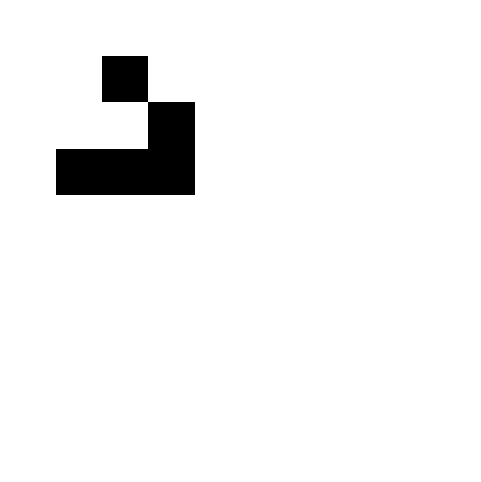

第 1 步后活细胞数：5
第 2 步后活细胞数：5
第 3 步后活细胞数：5
第 4 步后活细胞数：5


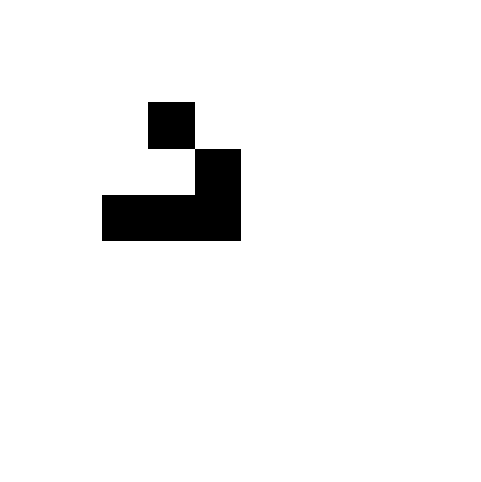

In [16]:
# 用经典的"滑翔机"(glider)演示：每 4 步整体平移一格
glider = np.zeros((10, 10), dtype=int)
glider[1, 2] = 1
glider[2, 3] = 1
glider[3, 1] = glider[3, 2] = glider[3, 3] = 1

print("初始活细胞数：", glider.sum())
draw_gol_board(glider)

state = glider.copy()
for step in range(1, 5):
    state = gol_step(state)
    print(f"第 {step} 步后活细胞数：{state.sum()}")
draw_gol_board(state)   # 4 步后与初始图形相同，只是向右下各平移一格

## 第三部分：使用 pandas DataFrame

读取 `Iris.csv`（列标题在第一行），回答数据规模、数据类型与列名，找出花卉种类数量；然后修正第 35、38 行（0 起始索引为 34、37）的错误数据，新增两个比值特征，另存为 `iris_corrected.csv`，最后按类别分组做五数统计。

In [17]:
import pandas as pd

pd.set_option("display.unicode.east_asian_width", True)

df = pd.read_csv("Iris.csv")

print("前 5 行：")
display(df.head())

print("\n数据点个数（行）：", df.shape[0], " 列数：", df.shape[1])
print("\n每一列的数据类型：")
print(df.dtypes)
print("\n列名：", list(df.columns))
print("\n花卉种类数：", df["Species"].nunique(), " 各类别：", list(df["Species"].unique()))
print("\n各类别样本数：")
print(df["Species"].value_counts())

前 5 行：


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa



数据点个数（行）： 150  列数： 6

每一列的数据类型：
Id                 int64
SepalLengthCm    float64
SepalWidthCm     float64
PetalLengthCm    float64
PetalWidthCm     float64
Species           object
dtype: object

列名： ['Id', 'SepalLengthCm', 'SepalWidthCm', 'PetalLengthCm', 'PetalWidthCm', 'Species']

花卉种类数： 3  各类别： ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']

各类别样本数：
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: Species, dtype: int64


### 修正第 35 行与第 38 行

- 第 35 个数据行（索引 34）：原文件第四项测量（PetalWidthCm）有误，改为 4.9, 3.1, 1.5, 0.2
- 第 38 个数据行（索引 37）：原文件第二、三项测量（SepalWidthCm、PetalLengthCm）有误，改为 4.9, 3.6, 1.4, 0.1

两行都属于 `Iris-setosa`（任务文字写作 setosa，为保持文件内命名统一，代码中仍写 `Iris-setosa`）。

In [18]:
print("修改前：")
display(df.loc[[34, 37], ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"]])

# 第 35 行（索引 34）
df.loc[34, ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"]] = [4.9, 3.1, 1.5, 0.2, "Iris-setosa"]
# 第 38 行（索引 37）
df.loc[37, ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"]] = [4.9, 3.6, 1.4, 0.1, "Iris-setosa"]

print("修改后：")
display(df.loc[[34, 37], ["SepalLengthCm", "SepalWidthCm", "PetalLengthCm", "PetalWidthCm", "Species"]])
print("现在一共有多少种花卉：", df["Species"].nunique(), list(df["Species"].unique()))
print("说明：任务中写作 setosa，这里为与文件原有命名一致，统一写成 Iris-setosa")

修改前：


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
34,4.9,3.1,1.5,0.1,Iris-setosa
37,4.9,3.1,1.5,0.1,Iris-setosa


修改后：


,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
34,4.9,3.1,1.5,0.2,Iris-setosa
37,4.9,3.6,1.4,0.1,Iris-setosa


现在一共有多少种花卉： 3 ['Iris-setosa', 'Iris-versicolor', 'Iris-virginica']
说明：任务中写作 setosa，这里为与文件原有命名一致，统一写成 Iris-setosa


In [19]:
# 新增两列比值特征
df["Petal.Ratio"] = df["PetalLengthCm"] / df["PetalWidthCm"]
df["Sepal.Ratio"] = df["SepalLengthCm"] / df["SepalWidthCm"]

print("新增列后前 5 行：")
display(df.head())

新增列后前 5 行：


,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species,Petal.Ratio,Sepal.Ratio
0,1,5.1,3.5,1.4,0.2,Iris-setosa,7.0,1.457143
1,2,4.9,3.0,1.4,0.2,Iris-setosa,7.0,1.633333
2,3,4.7,3.2,1.3,0.2,Iris-setosa,6.5,1.468750
3,4,4.6,3.1,1.5,0.2,Iris-setosa,7.5,1.483871
4,5,5.0,3.6,1.4,0.2,Iris-setosa,7.0,1.388889


In [20]:
# 保存修正与扩展后的数据，随作业一起提交
df.to_csv("iris_corrected.csv", index=False)
print("已保存 iris_corrected.csv，共", len(df), "行")

已保存 iris_corrected.csv，共 150 行


### 按花卉种类分组汇总

对 `Petal.Ratio` 与 `Sepal.Ratio` 一次求出平均值、中位数、最小值、最大值、标准差（`groupby` + `agg` 一条语句完成）。

In [21]:
summary = df.groupby("Species")[["Petal.Ratio", "Sepal.Ratio"]].agg(
    ["mean", "median", "min", "max", "std"]
)
summary.columns = pd.MultiIndex.from_product(
    [["Petal.Ratio", "Sepal.Ratio"], ["平均值", "中位数", "最小值", "最大值", "标准差"]]
)
display(summary.round(4))

Petal.Ratio                                Sepal.Ratio  \
                     平均值  中位数  最小值 最大值  标准差      平均值   
Species                                                                  
Iris-setosa          6.9080  7.0000  2.6667   15.0  2.8545      1.4702   
Iris-versicolor      3.2428  3.2404  2.6667    4.1  0.3125      2.1604   
Iris-virginica       2.7807  2.6667  2.1250    4.0  0.4074      2.2305   

                                                 
                 中位数  最小值  最大值  标准差  
Species                                          
Iris-setosa      1.4631  1.2683  1.9565  0.1187  
Iris-versicolor  2.1613  1.7647  2.8182  0.2287  
Iris-virginica   2.1695  1.8235  2.9615  0.2470